# Will This Visitor Buy? — Purchase Intent Classification
Business objective: estimate whether an online shopping session ends in a purchase and prioritize optional customer assistance. The positive class is relatively rare, so report recall, precision, F1 and PR-AUC rather than accuracy alone.

**Caution:** dataset sessions are aggregates, not timestamped live snapshots. `PageValues` is excluded because it can be transaction-associated. Treat this as a historical-session prototype; production inference requires pre-intervention event snapshots.

In [1]:
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import *
sns.set_theme(style="whitegrid")
ROOT=Path.cwd()
if not (ROOT/"README.md").exists() and (ROOT.parent/"README.md").exists(): ROOT=ROOT.parent
for d in ["data","models","reports"]: (ROOT/d).mkdir(exist_ok=True)

## 1. Data understanding
UCI reports 12,330 sessions, 17 predictors and the `Revenue` target; 10,422 sessions (84.5%) did not purchase and 1,908 (15.5%) did. The source reports no missing values.

In [2]:
path=ROOT/"data"/"online_shoppers_intention.csv"
if path.exists(): df=pd.read_csv(path)
else:
    from ucimlrepo import fetch_ucirepo
    ds=fetch_ucirepo(id=468); df=ds.data.features.copy(); df["Revenue"]=ds.data.targets.iloc[:,0].values
    df.to_csv(path,index=False)
print("Shape:",df.shape)
display(df.head(),df.dtypes.rename("dtype").to_frame(),df.isna().sum().rename("missing").to_frame())
display(df.describe(include="all").T)
display(pd.DataFrame({"dtype":df.dtypes.astype(str),"missing":df.isna().sum(),"unique":df.nunique()}))
y=df["Revenue"].astype(int)
display(y.value_counts().rename(index={0:"No purchase",1:"Purchase"}).to_frame("count"))

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


,missing
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


,dtype,missing,unique
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


,count
Revenue,
No purchase,10422
Purchase,1908


### Column dictionary
Each row represents one session. UCI describes the first six browsing variables as page counts and total time spent in each page category; `BounceRates` and `ExitRates` are Google Analytics measures; `SpecialDay` is closeness to a special day; and operating system, browser, region and traffic are coded categories. The duration unit is reported as the dataset records it.

| Column | Meaning |
|---|---|
| `Administrative`, `Informational`, `ProductRelated` | Number of visited pages in that page category during the session |
| `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` | Total recorded session time on pages in the corresponding category |
| `BounceRates` | Google Analytics bounce-rate measure for pages in the session |
| `ExitRates` | Google Analytics exit-rate measure for pages in the session |
| `PageValues` | Average page value associated with pages visited before a transaction; excluded from model inputs due to leakage / prediction-time availability concerns |
| `SpecialDay` | Closeness of the session date to a special day |
| `Month` | Month of the session |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Encoded category identifiers |
| `VisitorType` | Visitor category (new, returning, or other) |
| `Weekend` | Whether the session occurred on a weekend |
| `Revenue` | Target: whether the session ended in a purchase (`True` / 1) |

Source: [UCI dataset documentation](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), which also describes the class counts and source-variable definitions.

## 2. EDA — univariate, bivariate and multivariate

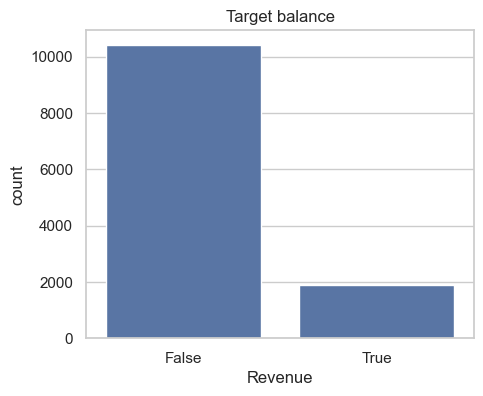

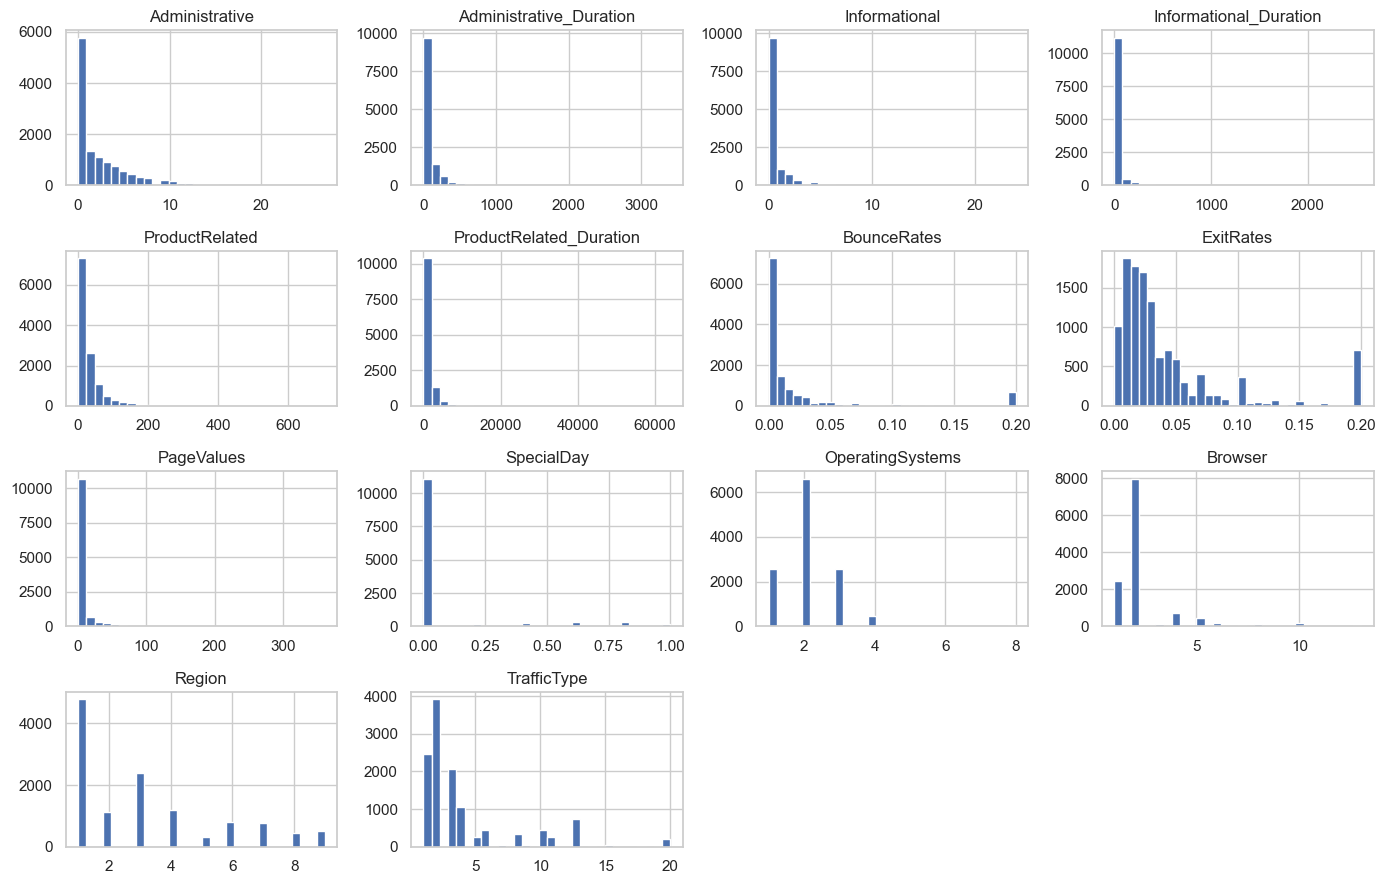

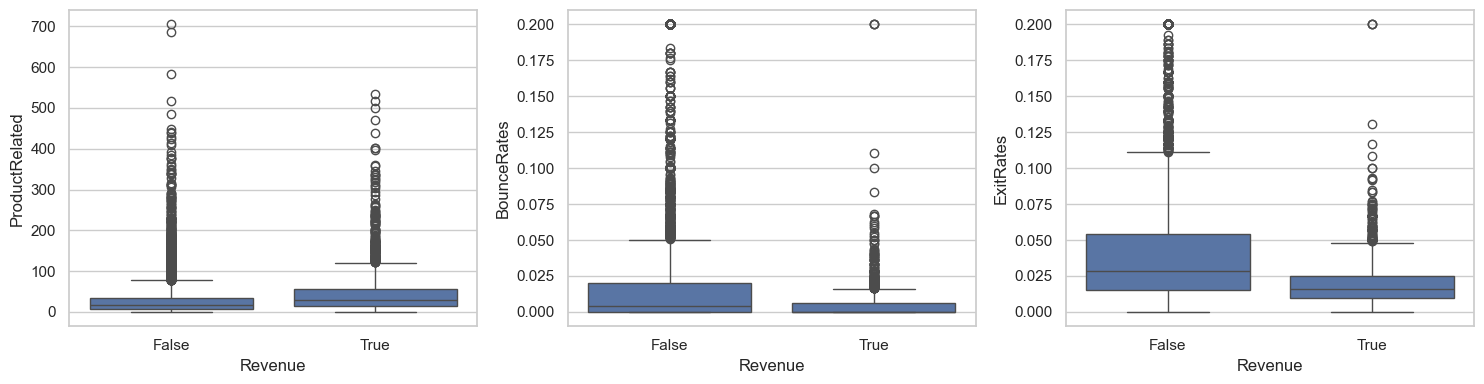

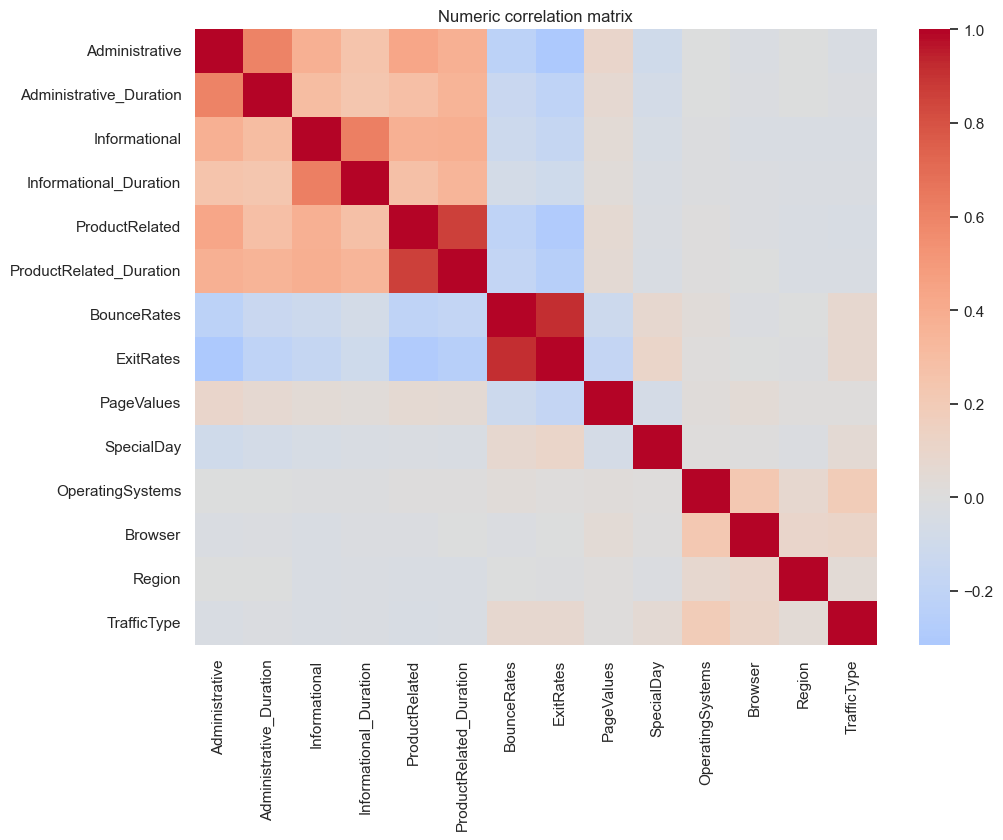

,observed_purchase_rate
VisitorType,
Returning_Visitor,0.139323
Other,0.188235
New_Visitor,0.249115


In [3]:
fig,ax=plt.subplots(figsize=(5,4)); sns.countplot(data=df,x="Revenue",ax=ax); ax.set_title("Target balance"); plt.show()
df.select_dtypes(include=np.number).hist(figsize=(14,9),bins=30); plt.tight_layout(); plt.show()
fig,axs=plt.subplots(1,3,figsize=(15,4))
for col,ax in zip(["ProductRelated","BounceRates","ExitRates"],axs): sns.boxplot(data=df,x="Revenue",y=col,ax=ax)
plt.tight_layout(); plt.show()
plt.figure(figsize=(11,8)); sns.heatmap(df.select_dtypes(include=np.number).corr(),cmap="coolwarm",center=0); plt.title("Numeric correlation matrix"); plt.show()
rate=df.assign(purchase=y).groupby("VisitorType").purchase.mean().sort_values()
display(rate.to_frame("observed_purchase_rate"))

### Evidence-based EDA insights (from the charts above)
1. The target is imbalanced: 1,908 of 12,330 sessions (15.5%) purchased, so a majority-class baseline misses every purchaser.
2. Purchasers viewed more product pages (median 29 vs. 16) and spent longer on them (median 1,109.9 vs. 510.2 seconds); these are associations, not causal effects.
3. Purchasers had lower median bounce rates (0.0000 vs. 0.0043) and exit rates (0.0160 vs. 0.0286).
4. Purchase rate differs by visitor type: 24.9% for new visitors versus 13.9% for returning visitors in this dataset.
5. Purchase rates vary by month (e.g., 25.4% in November and 1.6% in February); monthly rates should be interpreted cautiously because some months have few observations and this is historical data.

These descriptive comparisons inform hypotheses only; they do not establish that changing session behavior will cause a purchase.

## 3. Leakage-safe preprocessing
Split before fitting any transformations. Imputation, scaling and one-hot encoding live inside the pipeline. `PageValues` is intentionally excluded.

In [4]:
X=df.drop(columns=["Revenue","PageValues"])
cat=X.select_dtypes(include=["object","bool","category"]).columns.tolist()
num=X.columns.difference(cat).tolist()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
pre=ColumnTransformer([
 ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num),
 ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat)])
print(X_train.shape,X_test.shape,"numeric",num,"categorical",cat)

(9864, 16) (2466, 16) numeric ['Administrative', 'Administrative_Duration', 'BounceRates', 'Browser', 'ExitRates', 'Informational', 'Informational_Duration', 'OperatingSystems', 'ProductRelated', 'ProductRelated_Duration', 'Region', 'SpecialDay', 'TrafficType'] categorical ['Month', 'VisitorType', 'Weekend']


## 4. Baseline, models, cross-validation and tuning
Compare a majority DummyClassifier with Logistic Regression, Random Forest and Extra Trees. Tune on training data only using stratified 5-fold CV and F1.

In [5]:
cv=StratifiedKFold(5,shuffle=True,random_state=42)
dummy=Pipeline([("prep",pre),("model",DummyClassifier(strategy="most_frequent"))]).fit(X_train,y_train)
dp=dummy.predict(X_test)
print("Baseline precision/recall/F1:",precision_score(y_test,dp,zero_division=0),recall_score(y_test,dp,zero_division=0),f1_score(y_test,dp,zero_division=0))
spec={
 "Logistic Regression":(LogisticRegression(max_iter=2000,class_weight="balanced"),{"model__C":[.1,1,5]}),
 "Random Forest":(RandomForestClassifier(random_state=42,class_weight="balanced",n_jobs=-1),{"model__n_estimators":[200,400],"model__max_depth":[None,12,20],"model__min_samples_leaf":[1,3,5]}),
 "Extra Trees":(ExtraTreesClassifier(random_state=42,class_weight="balanced",n_jobs=-1),{"model__n_estimators":[200,400],"model__max_depth":[None,12,20],"model__min_samples_leaf":[1,3,5]})}
searches={}
for name,(est,params) in spec.items():
    pipe=Pipeline([("prep",pre),("model",est)])
    s=RandomizedSearchCV(pipe,params,n_iter=min(8,int(np.prod([len(v) for v in params.values()]))),scoring="f1",cv=cv,n_jobs=-1,random_state=42)
    s.fit(X_train,y_train); searches[name]=s
    print(name,"CV F1",s.best_score_,"params",s.best_params_)


Baseline precision/recall/F1: 0.0 0.0 0.0


Logistic Regression CV F1 0.3861001525207143 params {'model__C': 1}


Random Forest CV F1 0.4176353532195913 params {'model__n_estimators': 200, 'model__min_samples_leaf': 3, 'model__max_depth': 12}


Extra Trees CV F1 0.41573668610449266 params {'model__n_estimators': 400, 'model__min_samples_leaf': 3, 'model__max_depth': 20}


## 5. Final test evaluation and error analysis
Select by training-only mean CV F1. Evaluate once on the untouched test set at threshold 0.50. Any threshold selection must use training-only validation.

{
  "selected_model": "Random Forest",
  "best_cv_f1": 0.4176353532195913,
  "precision": 0.30082644628099175,
  "recall": 0.47643979057591623,
  "f1": 0.36879432624113473,
  "roc_auc": 0.7548449417652319,
  "pr_auc": 0.3425447314442088,
  "confusion_matrix": [
    [
      1661,
      423
    ],
    [
      200,
      182
    ]
  ],
  "threshold": 0.5,
  "best_params": {
    "model__n_estimators": 200,
    "model__min_samples_leaf": 3,
    "model__max_depth": 12
  }
}
              precision    recall  f1-score   support

           0       0.89      0.80      0.84      2084
           1       0.30      0.48      0.37       382

    accuracy                           0.75      2466
   macro avg       0.60      0.64      0.61      2466
weighted avg       0.80      0.75      0.77      2466



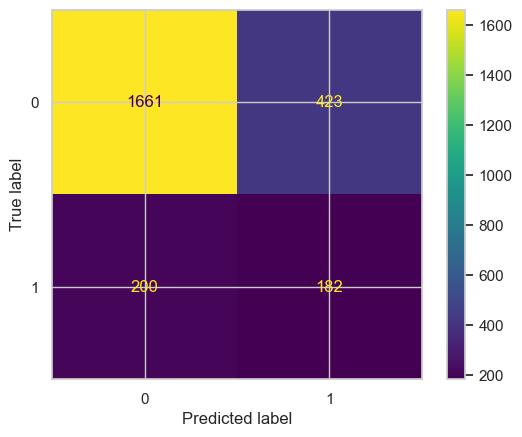

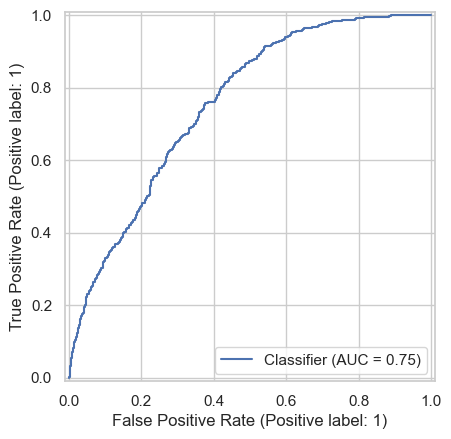

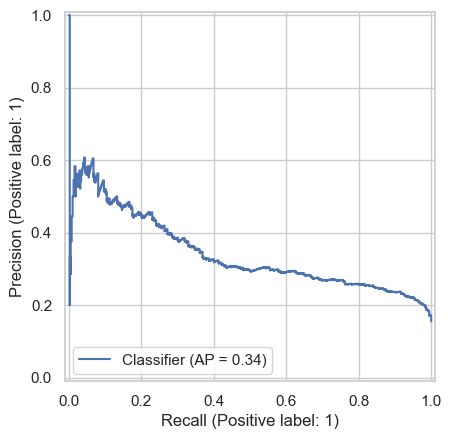

False positives: 423 False negatives: 200


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,actual,predicted,probability
5524,0,0.000000,0,0.0,6,95.000000,0.028571,0.028571,0.0,Oct,1,1,4,2,New_Visitor,False,1,0,0.335495
11507,3,67.750000,0,0.0,2,19.250000,0.040000,0.053333,0.0,Dec,1,1,3,20,New_Visitor,False,1,0,0.179482
11214,3,34.000000,1,1530.0,97,3989.485553,0.002000,0.012202,0.0,Nov,2,2,1,3,Returning_Visitor,True,0,1,0.585501
7656,0,0.000000,0,0.0,1,8.000000,0.000000,0.000000,0.0,Sep,2,2,2,1,Returning_Visitor,False,0,1,0.539299
10682,15,404.766667,4,240.5,120,4173.131061,0.006716,0.027928,0.0,Nov,2,2,3,2,Returning_Visitor,True,0,1,0.570195
7503,2,172.400000,3,134.0,15,569.493333,0.000000,0.025000,0.0,Sep,2,2,1,2,Returning_Visitor,True,0,1,0.564316
10561,2,190.750000,0,0.0,36,1604.791667,0.000000,0.012719,0.0,Dec,3,2,1,2,Returning_Visitor,True,0,1,0.642992
874,3,64.500000,0,0.0,35,1334.551371,0.000000,0.007310,0.0,Mar,3,2,4,2,Returning_Visitor,True,0,1,0.601840
2335,4,92.250000,1,0.0,47,1506.220833,0.000000,0.025596,0.4,May,2,2,1,2,Returning_Visitor,False,1,0,0.469718
12027,9,795.208333,0,0.0,118,4947.358038,0.001138,0.011201,0.0,Nov,3,2,5,2,Returning_Visitor,False,0,1,0.737909


,model,cv_best_f1,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
0,Dummy Classifier,NaN,0.0000,0.0000,0.0000,NaN,NaN
1,Logistic Regression,0.3861,0.2487,0.7356,0.3717,0.7317,0.3116
2,Random Forest,0.4176,0.3008,0.4764,0.3688,0.7548,0.3425
3,Extra Trees,0.4157,0.3092,0.5707,0.4011,0.7548,0.3565


In [6]:
best_name,best_search=max(searches.items(),key=lambda kv:kv[1].best_score_)
model=best_search.best_estimator_
proba=model.predict_proba(X_test)[:,1]; pred=(proba>=.5).astype(int)
metrics={"selected_model":best_name,"best_cv_f1":float(best_search.best_score_),
 "precision":float(precision_score(y_test,pred,zero_division=0)),
 "recall":float(recall_score(y_test,pred,zero_division=0)),
 "f1":float(f1_score(y_test,pred,zero_division=0)),
 "roc_auc":float(roc_auc_score(y_test,proba)),
 "pr_auc":float(average_precision_score(y_test,proba)),
 "confusion_matrix":confusion_matrix(y_test,pred).tolist(),
 "threshold":.5,"best_params":best_search.best_params_}
print(json.dumps(metrics,indent=2)); print(classification_report(y_test,pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,pred); plt.show()
RocCurveDisplay.from_predictions(y_test,proba); plt.show()
PrecisionRecallDisplay.from_predictions(y_test,proba); plt.show()
err=X_test.copy(); err["actual"]=y_test; err["predicted"]=pred; err["probability"]=proba
print("False positives:",((err.actual==0)&(err.predicted==1)).sum(),"False negatives:",((err.actual==1)&(err.predicted==0)).sum())
display(err[(err.actual!=err.predicted)].head(15))

comparison=[{"model":"Dummy Classifier","cv_best_f1":None,"test_precision":precision_score(y_test,dp,zero_division=0),"test_recall":recall_score(y_test,dp,zero_division=0),"test_f1":f1_score(y_test,dp,zero_division=0),"test_roc_auc":None,"test_pr_auc":None}]
for model_name,search in searches.items():
    score=search.best_estimator_.predict_proba(X_test)[:,1]; label=(score>=.5).astype(int)
    comparison.append({"model":model_name,"cv_best_f1":search.best_score_,"test_precision":precision_score(y_test,label,zero_division=0),"test_recall":recall_score(y_test,label,zero_division=0),"test_f1":f1_score(y_test,label,zero_division=0),"test_roc_auc":roc_auc_score(y_test,score),"test_pr_auc":average_precision_score(y_test,score)})
model_comparison=pd.DataFrame(comparison)
display(model_comparison.round(4))


## 6. Error analysis, business insight and limitations
The held-out confusion matrix is shown in the evaluation output. False positives (non-purchasing sessions flagged as buyers) could waste staff attention or incentive budget; false negatives (buyers missed by the model) could miss opportunities for optional assistance. At threshold 0.50, there are 423 false positives and 200 false negatives. The model catches 47.6% of actual purchasers, while only 30.1% of flagged sessions purchase.

Precision, recall and F1 describe the positive purchase class. ROC-AUC measures ranking across thresholds; PR-AUC is particularly informative with a 15.5% positive class (the no-skill reference is the positive prevalence). Accuracy alone would obscure the baseline's failure to find purchasers.

Use scores only to prioritize low-cost optional help for further evaluation. Do not automatically issue discounts: predicted intent does not show that an intervention causes incremental sales. Select thresholds using training-only validation and business costs, then test interventions with randomized A/B experiments.

Limitations: this is an educational prototype trained on historical session-level aggregates, which do not establish what data was available at a real-time decision point. The 125 duplicate records are retained to reproduce the supplied UCI dataset and split. `PageValues` is excluded because its transaction-associated value could leak the outcome and may not be known at intervention time. Validate calibration, temporal generalization, subgroup performance, and incremental lift on suitable live pre-intervention data before operational use.

In [7]:
joblib.dump(model,ROOT/"models"/"purchase_intent_pipeline.joblib")
(ROOT/"reports"/"test_metrics.json").write_text(json.dumps(metrics,indent=2))
model_comparison.to_csv(ROOT/"reports"/"model_comparison.csv",index=False)
print("Saved model and reports to",ROOT)


Saved model and reports to C:\Users\HP\Desktop\Uni\scholarships\NGI AI\purchase_intent_ml_project\purchase_intent_ml_project


## 7. Deployment and final checklist
Run `streamlit run app.py` after executing the notebook. Deploy `app.py` through Streamlit Community Cloud and add the public URL to the README.

- [ ] Restart & Run All succeeds
- [ ] EDA includes 3–5 verified written insights
- [ ] Pipeline prevents preprocessing leakage
- [ ] Baseline + three algorithms, CV and tuning included
- [ ] Untouched test metrics and error analysis reported
- [ ] Business recommendation and limitations explained
- [ ] Joblib model saved and app tested
- [ ] Public deployment, GitHub README, screenshots, 10–12 slide presentation and LinkedIn post completed
- [ ] Every reported number comes from your own run